# 阶段 2 · 作业 G：U-Net 的干净标签训练与 Noise2Noise 对比

目标：沿用作业 C 的合成图像与加噪方法，构造同一场景的两次独立噪声观测，使用作业 F 的小型 U-Net，比较干净标签训练和 Noise2Noise 训练的 PSNR。

把本文件放入 `assignments/10_unet_noise2noise/`，选择 `dl-env` 内核，按顺序运行。
只需要已有的 NumPy、Matplotlib、PyTorch；不下载数据，不依赖 d2l 或 torchvision。

| 训练方式 | 输入 | 训练目标 |
|---|---|---|
| N2C，干净标签训练 | $Y_1=S+\epsilon_1$ | 干净图 $S$ |
| N2N，Noise2Noise | 同一个 $Y_1$ | $Y_2=S+\epsilon_2$ |

两份噪声在给定干净场景后独立，均为零均值高斯噪声，标准差 0.08。目标是比较训练目标的影响。

本实验的干净图用于模拟观测、建立 N2C 基线及评价。N2N 分支的损失只接收第二张噪声图。
验证集的干净参考仅用于绘制诊断曲线；两组都固定训练 24 轮，使用最后一轮权重，不按干净验证分数挑选模型，也不依据测试集调整训练。

文件附有一次 CPU 参考运行输出。重新运行会替换成你的结果，最终以你机器上的运行结果填写作业。建议先运行到第 4 节，理解训练对后，再继续训练。


## 1. 设置设备、随机种子和实验规模

训练集 256 个场景，验证集和测试集各 32 个独立生成的场景；图像为 64×64。这里扩展作业 C 的几何图像做法，避免只在一张图上反复训练和测试。
`FORCE_CPU=True` 可用于 CPU 运行；默认优先使用可用的 CUDA。实际耗时取决于硬件。


In [1]:
import copy
import csv
import json
import os
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

FORCE_CPU = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() and not FORCE_CPU else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.manual_seed(2029)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(2029)
    torch.backends.cudnn.benchmark = False

CONFIG = {
    "image_size": 64, "train_size": 256, "val_size": 32, "test_size": 32,
    "sigma": 0.08, "batch_size": 16, "epochs": 24, "learning_rate": 0.001,
    "base_channels": 16, "data_range": 1.0, "initialization_seed": 2029,
    "train_scene_seed": 3101, "val_scene_seed": 3102, "test_scene_seed": 3103,
    "order_seed": 4100, "input_noise_seed": 5100, "target_noise_seed": 6100,
    "val_noise_seed": 7100, "test_noise_seed": 8100,
}

cwd = Path.cwd()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "assignments").is_dir()), None)
if PROJECT_ROOT is None:
    ASSIGNMENT_DIR = cwd
else:
    ASSIGNMENT_DIR = PROJECT_ROOT / "assignments" / "10_unet_noise2noise"
OUTPUT_DIR = ASSIGNMENT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_IMAGE_PATH = (PROJECT_ROOT / "assignments" / "04_noise_psnr" / "outputs" / "clean_image.npy"
                    if PROJECT_ROOT is not None else cwd / "clean_image.npy")

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("PyTorch：", torch.__version__, "设备：", DEVICE)
print("输出目录：", OUTPUT_DIR.resolve())
print("训练/验证/测试场景数：", CONFIG["train_size"], CONFIG["val_size"], CONFIG["test_size"])
print("固定训练轮数：", CONFIG["epochs"], "噪声标准差：", CONFIG["sigma"])


PyTorch： 2.5.1+cpu 设备： cpu
输出目录： [参考运行目录]/10_unet_noise2noise/outputs
训练/验证/测试场景数： 256 32 32
固定训练轮数： 24 噪声标准差： 0.08


## 2. 生成多场景图像，观察一个 Noise2Noise 训练对

沿用作业 C 中“背景渐变 + 几何图形 + 高斯噪声”的做法，改变图形位置、大小和亮度，生成不同场景。

下面的训练对示例优先读取作业 C 导出的 `outputs/clean_image.npy`。如果尚未导出，使用明确标记的合成示例；不会声称读取了你的原图。
可选：在作业 C 中，把干净数组保存为该路径的 `.npy`（例如 `np.save(目标路径, clean_image)`，变量名以你的原代码为准），再运行这一节。
这个原图入口只用于配对示例；主实验使用下面统一生成的多场景训练/验证/测试集。

两次调用 `randn` 分别生成噪声；不能把同一张噪声图复制一份作为标签，也不能直接在已有噪声图上继续加噪，假装得到独立观测。
噪声图不裁剪到 [0,1]，保持本次零均值加性噪声的设定。绘图中的 `vmin/vmax` 只控制显示。


配对示例来源： 同类方法生成的合成示例（未读取作业 C 原图）
A、B 噪声的样本相关系数： 0.0066
相关系数只是样本诊断；独立性由独立生成噪声的过程保证。


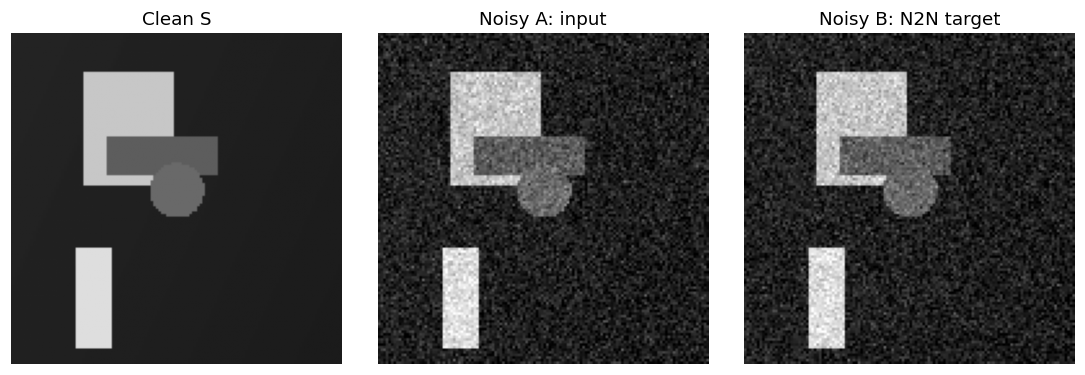

In [2]:
def make_clean_images(count, size, seed):
    rng = np.random.default_rng(seed)
    coordinates = np.linspace(-1, 1, size, dtype=np.float32)
    yy, xx = np.meshgrid(coordinates, coordinates, indexing="ij")
    images = []
    for _ in range(count):
        image = (rng.uniform(0.08, 0.18)
                 + rng.uniform(-0.035, 0.035) * xx
                 + rng.uniform(-0.035, 0.035) * yy)
        image = image.astype(np.float32)
        for _ in range(int(rng.integers(1, 4))):
            cx, cy = rng.uniform(-0.65, 0.65, size=2)
            half_w, half_h = rng.uniform(0.10, 0.38, size=2)
            rectangle = (np.abs(xx - cx) < half_w) & (np.abs(yy - cy) < half_h)
            image[rectangle] = rng.uniform(0.35, 0.9)
        for _ in range(int(rng.integers(1, 4))):
            cx, cy = rng.uniform(-0.65, 0.65, size=2)
            radius = rng.uniform(0.10, 0.35)
            circle = (xx - cx) ** 2 + (yy - cy) ** 2 < radius ** 2
            image[circle] = rng.uniform(0.35, 0.9)
        images.append(image)
    return torch.from_numpy(np.stack(images)).unsqueeze(1)


def add_noise(clean_cpu, generator):
    noise = CONFIG["sigma"] * torch.randn(clean_cpu.shape, generator=generator)
    return clean_cpu + noise


if CLEAN_IMAGE_PATH.is_file():
    original = np.load(CLEAN_IMAGE_PATH, allow_pickle=False).astype(np.float32)
    if original.ndim != 2 or not np.isfinite(original).all():
        raise ValueError("作业 C 原图必须是二维、有限数值的灰度数组。")
    if original.min() < 0 or original.max() > 1:
        raise ValueError("此入口要求作业 C 原图已经采用 [0,1] 强度标度。")
    demo_clean = torch.from_numpy(original)[None, None]
    demo_source = "作业 C 导出的 clean_image.npy"
else:
    demo_clean = make_clean_images(1, 128, seed=3000)
    demo_source = "同类方法生成的合成示例（未读取作业 C 原图）"

demo_a = add_noise(demo_clean, torch.Generator().manual_seed(3001))
demo_b = add_noise(demo_clean, torch.Generator().manual_seed(3002))
noise_a = (demo_a - demo_clean).numpy().ravel()
noise_b = (demo_b - demo_clean).numpy().ravel()
print("配对示例来源：", demo_source)
print("A、B 噪声的样本相关系数：", round(float(np.corrcoef(noise_a, noise_b)[0, 1]), 4))
print("相关系数只是样本诊断；独立性由独立生成噪声的过程保证。")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), constrained_layout=True)
for ax, tensor, title in zip(axes, [demo_clean, demo_a, demo_b],
                            ["Clean S", "Noisy A: input", "Noisy B: N2N target"]):
    ax.imshow(tensor[0, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
fig.savefig(OUTPUT_DIR / "training_pair.png", dpi=160)
plt.show()


## 3. 分开训练、验证、测试场景

三个集合使用不同随机种子，各自生成场景。训练时每轮重新采样噪声；验证和测试使用固定噪声，便于公平比较。
测试集只在两组训练结束后评价。模型不会在训练时看到测试场景。


In [3]:
train_clean = make_clean_images(CONFIG["train_size"], CONFIG["image_size"], CONFIG["train_scene_seed"])
val_clean = make_clean_images(CONFIG["val_size"], CONFIG["image_size"], CONFIG["val_scene_seed"])
test_clean = make_clean_images(CONFIG["test_size"], CONFIG["image_size"], CONFIG["test_scene_seed"])
val_noisy = add_noise(val_clean, torch.Generator().manual_seed(CONFIG["val_noise_seed"]))
test_noisy = add_noise(test_clean, torch.Generator().manual_seed(CONFIG["test_noise_seed"]))

for name, data in [("训练", train_clean), ("验证", val_clean), ("测试", test_clean)]:
    assert data.ndim == 4 and data.shape[1] == 1
    assert torch.isfinite(data).all() and data.min() >= 0 and data.max() <= 1
    print(name, tuple(data.shape))
assert len({CONFIG["train_scene_seed"], CONFIG["val_scene_seed"], CONFIG["test_scene_seed"]}) == 3


训练 (256, 1, 64, 64)
验证 (32, 1, 64, 64)
测试 (32, 1, 64, 64)


## 4. 复用作业 F 的小型 U-Net，建立完全相同的初始权重

仍然是两次下采样、基础通道数 16、两条拼接跳跃连接、线性输出，参数量 116,753。
两个模型通过复制同一个初始 `state_dict` 开始训练；它们有独立的参数存储，不会互相修改。
这次与作业 F 的区别是：后面会真正调用 `optimizer.step()` 更新参数。


In [4]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.layers(x)


class SmallUNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base_channels=16):
        super().__init__()
        self.in_channels = in_channels
        c = base_channels

        # 编码器：空间尺寸逐步减半，通道数增加
        self.enc1 = DoubleConv(in_channels, c)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.enc2 = DoubleConv(c, 2 * c)

        # 瓶颈
        self.bottleneck = DoubleConv(2 * c, 4 * c)

        # 解码器：上采样后，与编码器同尺度特征拼接
        self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(4 * c, 2 * c)
        self.up1 = nn.ConvTranspose2d(2 * c, c, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(2 * c, c)

        # 每个空间位置输出一个像素强度
        self.output_conv = nn.Conv2d(c, out_channels, kernel_size=1)

    def forward(self, x, return_features=False):
        if x.ndim != 4:
            raise ValueError("输入必须是四维张量 (N, C, H, W)。")
        if x.shape[1] != self.in_channels:
            raise ValueError(f"输入通道应为 {self.in_channels}，实际为 {x.shape[1]}。")
        height, width = x.shape[-2:]
        if height < 4 or width < 4 or height % 4 != 0 or width % 4 != 0:
            raise ValueError("本学习版要求高度、宽度至少为 4，且都为 4 的倍数。")

        e1 = self.enc1(x)
        p1 = self.pool(e1)
        e2 = self.enc2(p1)
        p2 = self.pool(e2)
        b = self.bottleneck(p2)

        u2 = self.up2(b)
        c2 = torch.cat([u2, e2], dim=1)
        d2 = self.dec2(c2)

        u1 = self.up1(d2)
        c1 = torch.cat([u1, e1], dim=1)
        d1 = self.dec1(c1)
        output = self.output_conv(d1)

        if return_features:
            features = {
                "input": x, "enc1": e1, "pool1": p1,
                "enc2": e2, "pool2": p2, "bottleneck": b,
                "up2": u2, "concat2": c2, "dec2": d2,
                "up1": u1, "concat1": c1, "dec1": d1,
                "output": output,
            }
            return output, features
        return output

torch.manual_seed(CONFIG["initialization_seed"])
initial_model = SmallUNet(base_channels=CONFIG["base_channels"])
initial_state = copy.deepcopy(initial_model.state_dict())
model_n2c = copy.deepcopy(initial_model).to(DEVICE)
model_n2n = copy.deepcopy(initial_model).to(DEVICE)
del initial_model

assert all(torch.equal(a.detach().cpu(), b.detach().cpu())
           for a, b in zip(model_n2c.parameters(), model_n2n.parameters()))
assert all(a.data_ptr() != b.data_ptr()
           for a, b in zip(model_n2c.parameters(), model_n2n.parameters()))
parameter_count = sum(p.numel() for p in model_n2c.parameters() if p.requires_grad)
assert parameter_count == 116753
print("每个模型的可训练参数量：", parameter_count)
print("初始参数完全相同，参数存储相互独立。")


每个模型的可训练参数量： 116753
初始参数完全相同，参数存储相互独立。


## 5. 定义 PSNR、预测和训练函数

PSNR 使用干净图的固定强度标度 `data_range=1.0`：

$$\mathrm{PSNR}=10\log_{10}\frac{1^2}{\mathrm{MSE}}.$$

先逐图计算 PSNR，再取图像之间的平均值。评价使用原始输出，不先裁剪；所有方法使用同一标准。

每个 epoch 的样本顺序和输入噪声，对 N2C / N2N 都相同。N2N 目标噪声由另一个随机数生成器产生。
训练循环执行 `zero_grad → forward → loss → backward → step`。
`running_loss` 累加每批均值乘以本批图片数，最后除以总图片数。

N2N 的训练目标带噪，所以它的训练 MSE 通常存在约 $\sigma^2=0.0064$ 的额外噪声项。不能仅凭两条训练 loss 的高低判断哪组去噪更好；比较统一干净参考下的 PSNR。


In [5]:
def psnr_per_image(prediction, reference):
    assert prediction.shape == reference.shape
    mse = (prediction - reference).square().flatten(1).mean(dim=1)
    return 10 * torch.log10(CONFIG["data_range"] ** 2 / mse.clamp_min(1e-12))


@torch.no_grad()
def predict_batches(model, noisy_cpu):
    model.eval()
    predictions = []
    for start in range(0, len(noisy_cpu), CONFIG["batch_size"]):
        x = noisy_cpu[start:start + CONFIG["batch_size"]].to(DEVICE)
        predictions.append(model(x).cpu())
    result = torch.cat(predictions)
    assert torch.isfinite(result).all()
    return result


def train_model(model, mode):
    if mode not in {"n2c", "n2n"}:
        raise ValueError("mode 必须是 n2c 或 n2n。")
    optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
    criterion = nn.MSELoss()
    history = []
    updates = 0
    start_time = time.perf_counter()

    for epoch in range(1, CONFIG["epochs"] + 1):
        order_generator = torch.Generator().manual_seed(CONFIG["order_seed"] + epoch)
        input_generator = torch.Generator().manual_seed(CONFIG["input_noise_seed"] + epoch)
        target_generator = torch.Generator().manual_seed(CONFIG["target_noise_seed"] + epoch)
        loader = DataLoader(TensorDataset(train_clean), batch_size=CONFIG["batch_size"],
                            shuffle=True, generator=order_generator, num_workers=0)
        model.train()
        running_loss = 0.0
        seen = 0
        for (clean_cpu,) in loader:
            input_cpu = add_noise(clean_cpu, input_generator)
            target_cpu = clean_cpu if mode == "n2c" else add_noise(clean_cpu, target_generator)
            inputs = input_cpu.to(DEVICE)
            targets = target_cpu.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            prediction = model(inputs)
            loss = criterion(prediction, targets)
            if not torch.isfinite(loss).item():
                raise RuntimeError("训练损失出现非有限数值。")
            loss.backward()
            optimizer.step()
            updates += 1
            running_loss += loss.item() * len(clean_cpu)
            seen += len(clean_cpu)

        val_prediction = predict_batches(model, val_noisy)
        val_psnr = float(psnr_per_image(val_prediction, val_clean).mean())
        row = {"epoch": epoch, "train_loss": running_loss / seen, "val_psnr_db": val_psnr}
        history.append(row)
        if epoch == 1 or epoch % 5 == 0 or epoch == CONFIG["epochs"]:
            print(f"{mode.upper()} | epoch {epoch:2d}/{CONFIG['epochs']} | "
                  f"train loss {row['train_loss']:.6f} | val PSNR {val_psnr:.2f} dB", flush=True)

    return history, updates, time.perf_counter() - start_time


print("已定义训练函数；这一节尚未开始训练。")
print("高斯噪声的理论输入 PSNR 参考：", round(-20 * np.log10(CONFIG["sigma"]), 2), "dB")


已定义训练函数；这一节尚未开始训练。
高斯噪声的理论输入 PSNR 参考： 21.94 dB


## 6. 分别训练 N2C 和 N2N

两组均训练相同轮数，使用同一网络、初始化、学习率、样本顺序和输入噪声，只改变目标。
每 5 轮打印一次进度。这里第一次真正更新 U-Net 参数。

如果重新比较，先重新运行第 4 节，让两个模型回到相同初始状态，再运行本节；只重复本节会继续训练已有模型。


In [6]:
# 防止只重复本节而意外进行二次训练。
for current_model in [model_n2c, model_n2n]:
    if not all(torch.equal(value.detach().cpu(), initial_state[name])
               for name, value in current_model.state_dict().items()):
        raise RuntimeError("模型已训练。请先重新运行第 4 节，重建相同初始参数。")

history_n2c, updates_n2c, seconds_n2c = train_model(model_n2c, "n2c")
history_n2n, updates_n2n, seconds_n2n = train_model(model_n2n, "n2n")
assert updates_n2c == updates_n2n
assert any(not torch.equal(v.detach().cpu(), initial_state[k])
           for k, v in model_n2c.state_dict().items())
assert any(not torch.equal(v.detach().cpu(), initial_state[k])
           for k, v in model_n2n.state_dict().items())
print("每组参数更新次数：", updates_n2c)
print(f"参考本次耗时：N2C {seconds_n2c:.1f} s；N2N {seconds_n2n:.1f} s")


N2C | epoch  1/24 | train loss 0.046333 | val PSNR 16.28 dB
N2C | epoch  5/24 | train loss 0.002888 | val PSNR 26.36 dB
N2C | epoch 10/24 | train loss 0.001507 | val PSNR 29.03 dB
N2C | epoch 15/24 | train loss 0.000985 | val PSNR 30.69 dB
N2C | epoch 20/24 | train loss 0.000790 | val PSNR 31.74 dB
N2C | epoch 24/24 | train loss 0.000656 | val PSNR 32.36 dB
N2N | epoch  1/24 | train loss 0.052722 | val PSNR 16.28 dB
N2N | epoch  5/24 | train loss 0.009228 | val PSNR 26.38 dB
N2N | epoch 10/24 | train loss 0.007779 | val PSNR 29.28 dB
N2N | epoch 15/24 | train loss 0.007451 | val PSNR 30.44 dB
N2N | epoch 20/24 | train loss 0.007225 | val PSNR 31.41 dB
N2N | epoch 24/24 | train loss 0.007089 | val PSNR 32.10 dB
每组参数更新次数： 384
参考本次耗时：N2C 92.7 s；N2N 50.3 s


## 7. 在相同测试集上比较 PSNR

两组都使用训练结束时的权重。输入为同一批此前未参与训练的测试噪声图，参考为对应的测试干净图。
报告平均 PSNR、图像间标准差、相对输入的提升，以及 `N2C − N2N` 的差值。差值为负表示本次 N2N 分数更高。

理论讨论的是期望风险的最优解；有限样本、有限训练轮数下不要求 PSNR 完全一致，也不存在必须达到的固定差值。


In [7]:
prediction_n2c = predict_batches(model_n2c, test_noisy)
prediction_n2n = predict_batches(model_n2n, test_noisy)
scores = {
    "Noisy input": psnr_per_image(test_noisy, test_clean),
    "N2C": psnr_per_image(prediction_n2c, test_clean),
    "N2N": psnr_per_image(prediction_n2n, test_clean),
}
baseline_mean = float(scores["Noisy input"].mean())
summary = []
for method, values in scores.items():
    row = {"method": method, "mean_psnr_db": float(values.mean()),
           "std_psnr_db": float(values.std(unbiased=True)),
           "gain_over_input_db": float(values.mean()) - baseline_mean}
    summary.append(row)
    print(f"{method:12s} | PSNR {row['mean_psnr_db']:.3f} ± {row['std_psnr_db']:.3f} dB | "
          f"相对输入 {row['gain_over_input_db']:+.3f} dB")

gap_db = float(scores["N2C"].mean() - scores["N2N"].mean())
print(f"N2C − N2N：{gap_db:+.3f} dB")


Noisy input  | PSNR 21.958 ± 0.088 dB | 相对输入 +0.000 dB
N2C          | PSNR 32.406 ± 1.797 dB | 相对输入 +10.448 dB
N2N          | PSNR 32.201 ± 1.831 dB | 相对输入 +10.242 dB
N2C − N2N：+0.205 dB


## 8. 保存训练曲线与图像对比

图像固定展示测试集的前两张，不挑最好看的样本。统一使用灰度范围 [0,1] 显示；PSNR 仍使用未经裁剪的数值。
右侧验证 PSNR 曲线使用同一干净参考，适合比较两种训练的进展。左侧训练 loss 的目标不同，不能直接把更低的 loss 等同于更好的去噪。


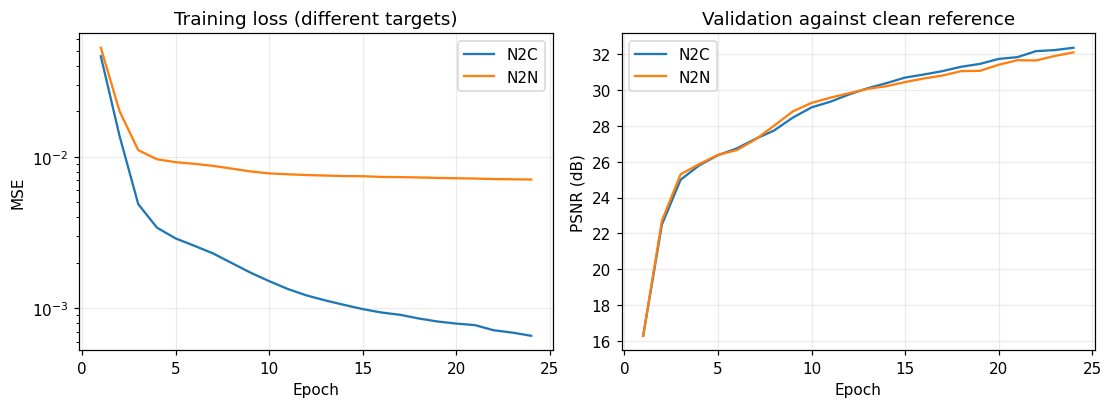

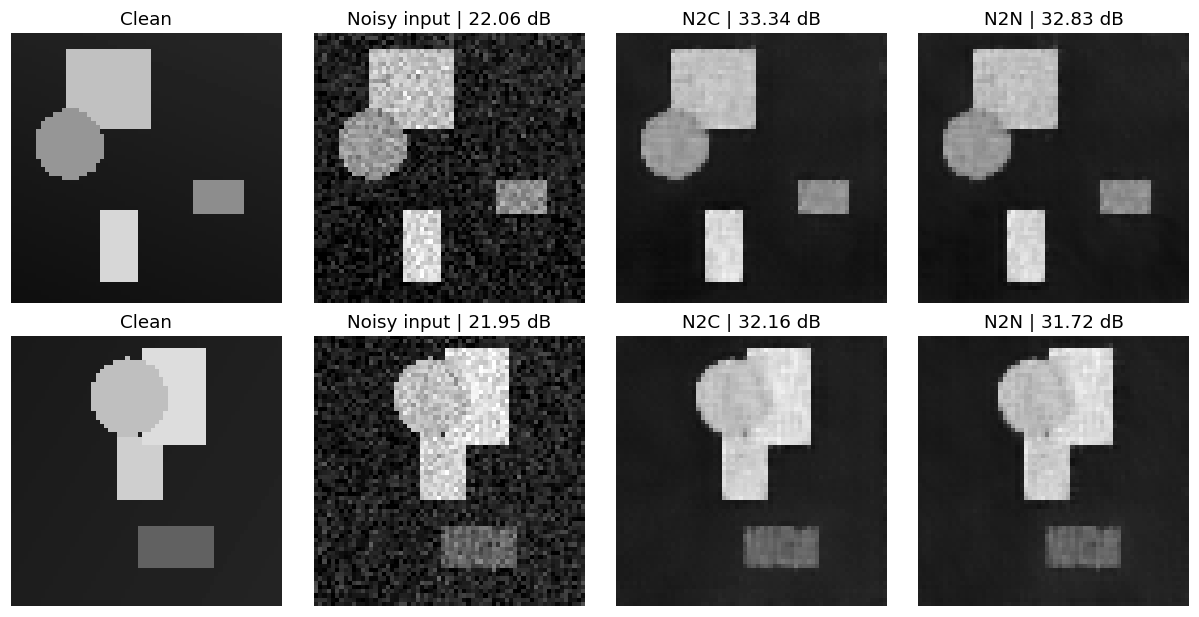

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), constrained_layout=True)
for label, history in [("N2C", history_n2c), ("N2N", history_n2n)]:
    epochs = [row["epoch"] for row in history]
    axes[0].plot(epochs, [row["train_loss"] for row in history], label=label)
    axes[1].plot(epochs, [row["val_psnr_db"] for row in history], label=label)
axes[0].set(title="Training loss (different targets)", xlabel="Epoch", ylabel="MSE", yscale="log")
axes[1].set(title="Validation against clean reference", xlabel="Epoch", ylabel="PSNR (dB)")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.savefig(OUTPUT_DIR / "training_curves.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(11, 5.5), constrained_layout=True)
for row_index in range(2):
    tensors = [test_clean, test_noisy, prediction_n2c, prediction_n2n]
    titles = ["Clean", "Noisy input", "N2C", "N2N"]
    for ax, tensor, title in zip(axes[row_index], tensors, titles):
        ax.imshow(tensor[row_index, 0], cmap="gray", vmin=0, vmax=1)
        suffix = "" if title == "Clean" else f" | {scores[title][row_index]:.2f} dB"
        ax.set_title(title + suffix)
        ax.axis("off")
fig.savefig(OUTPUT_DIR / "denoising_comparison.png", dpi=160)
plt.show()


## 9. 为什么只用噪声标签也能学习？

令干净图为 $S$，输入为 $Y_1=S+\epsilon_1$，N2N 目标为 $Y_2=S+\epsilon_2$。
本实验分别生成两份零均值噪声，满足 $\mathbb E[\epsilon_2\mid S,Y_1]=0$。
设每张图有 $P$ 个像素。将 N2N 的平方损失展开：

$$\mathbb E\frac{\|f_\theta(Y_1)-Y_2\|^2}{P}
=\mathbb E\frac{\|f_\theta(Y_1)-S\|^2}{P}
-\frac{2}{P}\mathbb E\langle f_\theta(Y_1)-S,\epsilon_2\rangle
+\mathbb E\frac{\|\epsilon_2\|^2}{P}.$$

条件零均值使交叉项为零。本实验的目标噪声方差为 $\sigma^2$，因此：

$$\boxed{L_{\mathrm{N2N}}(\theta)=L_{\mathrm{N2C}}(\theta)+\sigma^2.}$$

额外项与参数 $\theta$ 无关，因此在期望意义下，两者的最优解集合相同。
这不意味着任何单个 noisy target 都等于干净图，也不意味着一次有限训练会得到完全相同的权重或 PSNR。

若把同一张噪声图同时作为输入和目标，复制输入就能得到零损失，不能据此学会去噪。
若直接令 $Y_2=Y_1+\epsilon_2$，两张图共享原有噪声，条件均值也不会自动变回干净图 $S$。

本项学习的是 Noise2Noise 原理与训练流程。SN2N 还需要自己的训练对构造等设计；本实验不代表完整复现 SN2N，也不能直接推出真实显微图像上的性能。

原始论文：[Lehtinen 等，Noise2Noise，ICML 2018](https://proceedings.mlr.press/v80/lehtinen18a.html)。


## 10. 保存模型、结果和一篇重点笔记

保存的是两组最后一轮权重。`obsidian_noise2noise.md` 自动填写本次真实结果；运行后将它放到现有 Obsidian 仓库的 `01-learning-notes`，或把重点合并进已有“神经网络”笔记即可。
本实验只在这里整理一次笔记。

完成标准：理解独立噪声对；两组模型完成相同更新次数；报告同一测试集 PSNR；解释期望最优解相同的条件。比较结果由实际运行决定。


In [9]:
results = {
    "config": CONFIG, "torch_version": torch.__version__, "device": str(DEVICE),
    "demo_source": demo_source, "parameter_count": parameter_count,
    "checkpoint_policy": "last_epoch_fixed_budget_no_clean_validation_selection",
    "evaluation": "mean_of_per_image_psnr_raw_predictions_data_range_1",
    "summary": summary, "n2c_minus_n2n_db": gap_db,
    "updates": {"n2c": updates_n2c, "n2n": updates_n2n},
    "seconds": {"n2c": seconds_n2c, "n2n": seconds_n2n},
}
(OUTPUT_DIR / "metrics.json").write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding="utf-8")
(OUTPUT_DIR / "training_history.json").write_text(
    json.dumps({"n2c": history_n2c, "n2n": history_n2n}, indent=2), encoding="utf-8")
with (OUTPUT_DIR / "psnr_per_image.csv").open("w", newline="", encoding="utf-8-sig") as file:
    writer = csv.writer(file)
    writer.writerow(["image_index", "noisy_psnr_db", "n2c_psnr_db", "n2n_psnr_db"])
    for index in range(len(test_clean)):
        writer.writerow([index, *(float(scores[key][index]) for key in ["Noisy input", "N2C", "N2N"])])

for mode, model in [("n2c", model_n2c), ("n2n", model_n2n)]:
    cpu_state = {name: value.detach().cpu() for name, value in model.state_dict().items()}
    torch.save({"state_dict": cpu_state, "config": CONFIG, "training_mode": mode},
               OUTPUT_DIR / f"unet_{mode}_final.pt")

metric_lines = "\n".join(
    f"- {row['method']}：平均 PSNR {row['mean_psnr_db']:.3f} dB；相对输入 {row['gain_over_input_db']:+.3f} dB。"
    for row in summary)
note = rf"""# Noise2Noise：为什么噪声标签也能训练去噪网络

## 本次实验

- 复用两次下采样的小型 U-Net，每个模型 {parameter_count:,} 个参数。
- 灰度几何场景 64×64，训练/验证/测试为 256/32/32，使用不同场景。
- 高斯噪声标准差 {CONFIG['sigma']}；每轮重新生成训练噪声；不裁剪噪声值。
- N2C：噪声 A → 干净图；N2N：噪声 A → 同场景的独立噪声 B。
- 两组初始化、输入、样本顺序、优化器、学习率、轮数相同，各更新 {updates_n2c} 次。
- 固定训练 {CONFIG['epochs']} 轮，评价最后一轮模型；不按干净验证分数挑模型。
- 验证、测试 PSNR 使用干净参考，N2N 训练损失不使用干净标签。

## 实际运行结果

{metric_lines}
- N2C − N2N：{gap_db:+.3f} dB。
- 指标口径：对未经裁剪的输出逐图计算 PSNR，再取平均；data_range 固定为 1。
- 这是一次合成数据实验，不能当作真实显微图像或完整 SN2N 的性能。

## 原理与条件

同一场景的两次观测为 $Y_1=S+\epsilon_1$、$Y_2=S+\epsilon_2$。
目标噪声满足 $\mathbb E[\epsilon_2\mid S,Y_1]=0$。
展开平方损失后，交叉项的期望为零，因此

$$L_{{N2N}}(\theta)=L_{{N2C}}(\theta)+\sigma^2.$$

额外项与参数无关，所以期望风险的最优解相同。有限数据和有限训练仍可能造成 PSNR 差距。
同一噪声图自我复制不满足本实验条件；在已有噪声图上继续加噪也不能直接构成独立观测。
N2N 的训练 loss 包含目标噪声项，因此评价去噪时应使用统一的参考和指标。

## 训练循环

zero_grad 清除旧梯度；forward 计算预测；loss 衡量误差；backward 计算梯度；optimizer.step 更新参数。

来源：[Noise2Noise 原论文](https://proceedings.mlr.press/v80/lehtinen18a.html)。
"""
(OUTPUT_DIR / "obsidian_noise2noise.md").write_text(note, encoding="utf-8")
print("已保存：")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(path.name)


已保存：
denoising_comparison.png
metrics.json
obsidian_noise2noise.md
psnr_per_image.csv
training_curves.png
training_history.json
training_pair.png
unet_n2c_final.pt
unet_n2n_final.pt
